In [3]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style("whitegrid")


In [2]:
# Load dataset

df = pd.read_csv("Unemployment in India.csv")

# Display first five rows

df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [4]:
df.tail()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
764,NaN,NaN,NaN,NaN,NaN,NaN,NaN
765,NaN,NaN,NaN,NaN,NaN,NaN,NaN
766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
767,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Check dataset shape

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 768
Number of Columns: 7


In [6]:
# Display column names

print(df.columns.tolist())

['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


In [7]:
df.columns = df.columns.str.strip()

print(df.columns)

Index(['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)',
       'Estimated Employed', 'Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')


In [8]:
#Data Cleaning and Preprocessing
df.columns = df.columns.str.strip()

print(df.columns)

Index(['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)',
       'Estimated Employed', 'Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')


In [9]:
#Checking Missing Values
print(df.isnull().sum())

Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64


In [10]:
df.duplicated().sum()

np.int64(27)

In [11]:
df.drop_duplicates()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural
...,...,...,...,...,...,...,...
749,West Bengal,29-02-2020,Monthly,7.55,10871168.0,44.09,Urban
750,West Bengal,31-03-2020,Monthly,6.67,10806105.0,43.34,Urban
751,West Bengal,30-04-2020,Monthly,15.63,9299466.0,41.20,Urban
752,West Bengal,31-05-2020,Monthly,15.22,9240903.0,40.67,Urban


In [13]:
#Handling Missing Values
# Separate numerical and categorical columns

numeric_columns = df.select_dtypes(include=np.number).columns

categorical_columns = df.select_dtypes(include='object').columns

# Fill missing numerical values with median

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode

for col in categorical_columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])


In [14]:
# Convert date into datetime format

df['Date'] = pd.to_datetime(
    df['Date'],
    dayfirst=True,
    errors='coerce'
)

# Remove invalid dates

df = df.dropna(subset=['Date'])

print(df['Date'].head())

0   2019-05-31
1   2019-06-30
2   2019-07-31
3   2019-08-31
4   2019-09-30
Name: Date, dtype: datetime64[ns]


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   768 non-null    object        
 1   Date                                     768 non-null    datetime64[ns]
 2   Frequency                                768 non-null    object        
 3   Estimated Unemployment Rate (%)          768 non-null    float64       
 4   Estimated Employed                       768 non-null    float64       
 5   Estimated Labour Participation Rate (%)  768 non-null    float64       
 6   Area                                     768 non-null    object        
dtypes: datetime64[ns](1), float64(3), object(3)
memory usage: 42.1+ KB


In [16]:
df.describe()

,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,768,768.000000,7.680000e+02,768.000000
mean,2019-12-12 07:26:14.999999744,11.662604,7.114762e+06,42.576523
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.720000,1.376532e+06,38.265000
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.472500,1.111390e+07,45.362500
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.543518,7.952384e+06,7.966439


In [17]:
print("Total Regions:", df['Region'].nunique())

print("\nAvailable Regions:")

print(df['Region'].unique())

Total Regions: 28

Available Regions:
['Andhra Pradesh' 'Assam' 'Bihar' 'Chhattisgarh' 'Delhi' 'Goa' 'Gujarat'
 'Haryana' 'Himachal Pradesh' 'Jammu & Kashmir' 'Jharkhand' 'Karnataka'
 'Kerala' 'Madhya Pradesh' 'Maharashtra' 'Meghalaya' 'Odisha' 'Puducherry'
 'Punjab' 'Rajasthan' 'Sikkim' 'Tamil Nadu' 'Telangana' 'Tripura'
 'Uttar Pradesh' 'Uttarakhand' 'West Bengal' 'Chandigarh']


In [18]:
print(df['Area'].value_counts())

Area
Urban    409
Rural    359
Name: count, dtype: int64


In [19]:
#Calculating Average Unemployment Rate
average_unemployment = df[
    'Estimated Unemployment Rate (%)'
].mean()

print("Average Unemployment Rate:", round(average_unemployment, 2), "%")

Average Unemployment Rate: 11.66 %


In [20]:
#Finding Maximum and Minimum Unemployment rates
max_rate = df['Estimated Unemployment Rate (%)'].max()

min_rate = df['Estimated Unemployment Rate (%)'].min()

print("Maximum Unemployment Rate:", max_rate)

print("Minimum Unemployment Rate:", min_rate)

Maximum Unemployment Rate: 76.74
Minimum Unemployment Rate: 0.0


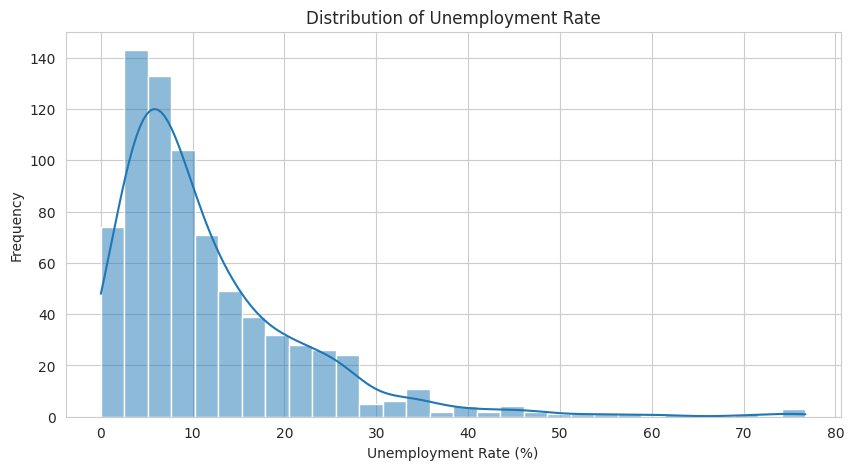

In [21]:
#Data Visualization
#Visualization 1 : Unemployment Rate Distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Estimated Unemployment Rate (%)'],
    bins=30,
    kde=True
)

plt.title("Distribution of Unemployment Rate")

plt.xlabel("Unemployment Rate (%)")

plt.ylabel("Frequency")

plt.show()

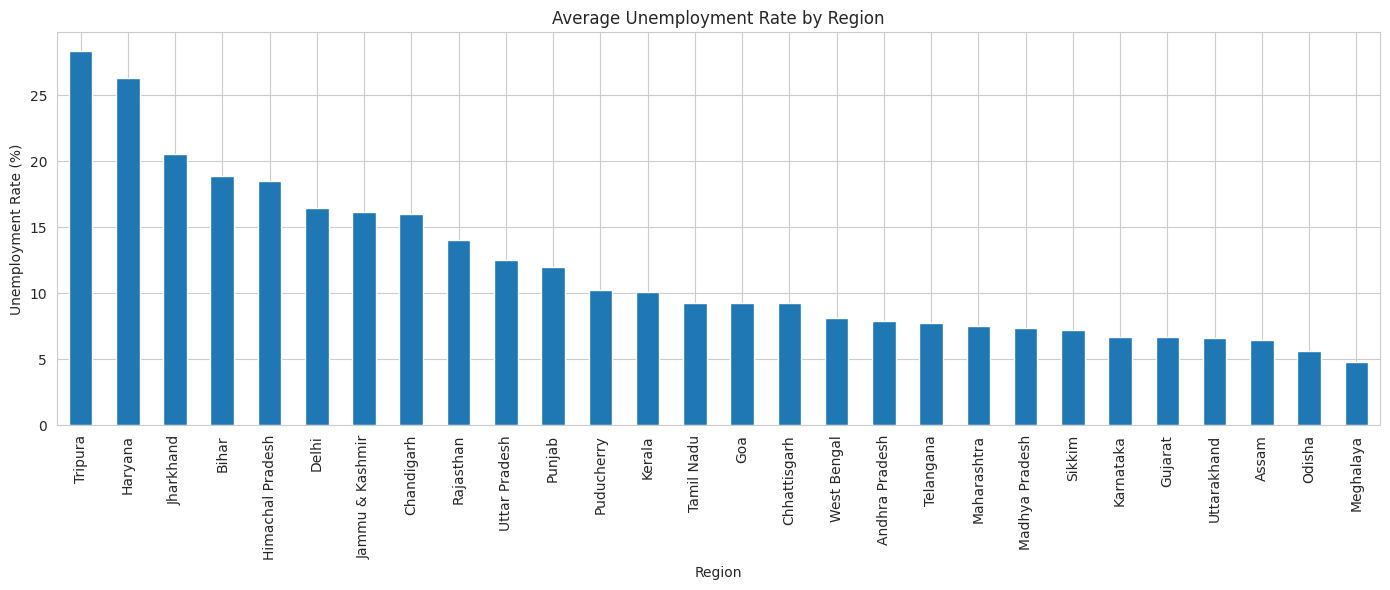

In [23]:
#Visualization 2: Unemployment Rate by Region
region_data = df.groupby('Region')[
    'Estimated Unemployment Rate (%)'
].mean().sort_values(ascending=False)

plt.figure(figsize=(14, 6))

region_data.plot(kind='bar')

plt.title("Average Unemployment Rate by Region")

plt.xlabel("Region")

plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=90)

plt.tight_layout()

plt.show()

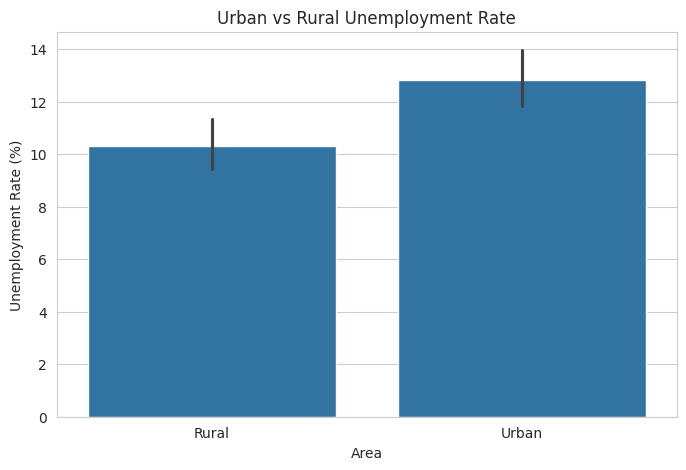

In [24]:
#Visualization 3: Urban vs Rural Unemployment
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Area',
    y='Estimated Unemployment Rate (%)'
)

plt.title("Urban vs Rural Unemployment Rate")

plt.xlabel("Area")

plt.ylabel("Unemployment Rate (%)")

plt.show()

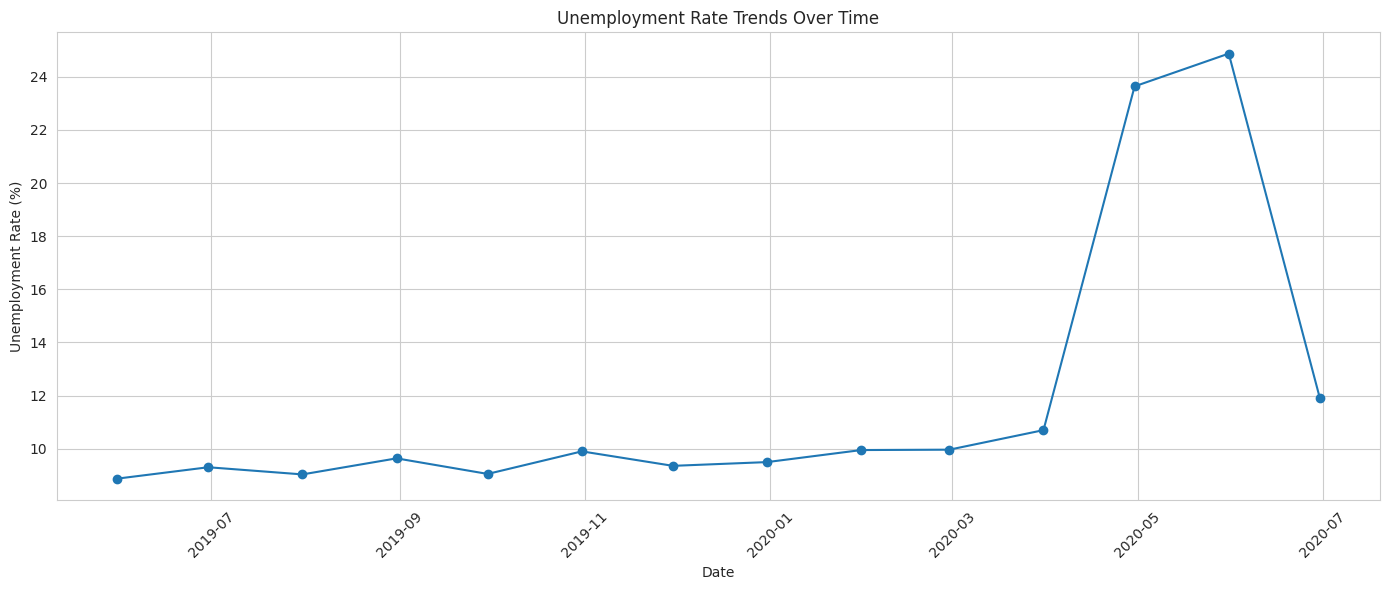

In [25]:
#7. Unemployment Trends Over Time
# Sort data by date

df = df.sort_values('Date')

# Calculate average unemployment by date

date_trend = df.groupby('Date')[
    'Estimated Unemployment Rate (%)'
].mean()

# Plot trend

plt.figure(figsize=(14, 6))

plt.plot(
    date_trend.index,
    date_trend.values,
    marker='o'
)

plt.title("Unemployment Rate Trends Over Time")

plt.xlabel("Date")

plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=45)

plt.grid(True)

plt.tight_layout()

plt.show()

In [26]:
def covid_period(date):

    if date < pd.Timestamp('2020-03-01'):
        return 'Before COVID-19'

    elif date <= pd.Timestamp('2021-12-31'):
        return 'During COVID-19'

    else:
        return 'After COVID-19'


df['COVID_Period'] = df['Date'].apply(covid_period)

print(df[['Date', 'COVID_Period']].head())

          Date     COVID_Period
0   2019-05-31  Before COVID-19
189 2019-05-31  Before COVID-19
740 2019-05-31  Before COVID-19
519 2019-05-31  Before COVID-19
40  2019-05-31  Before COVID-19


In [27]:
#Calculate unemployment rate by COVID period
covid_analysis = df.groupby('COVID_Period')[
    'Estimated Unemployment Rate (%)'
].mean()

print(covid_analysis)

COVID_Period
Before COVID-19     9.451968
During COVID-19    17.774363
Name: Estimated Unemployment Rate (%), dtype: float64


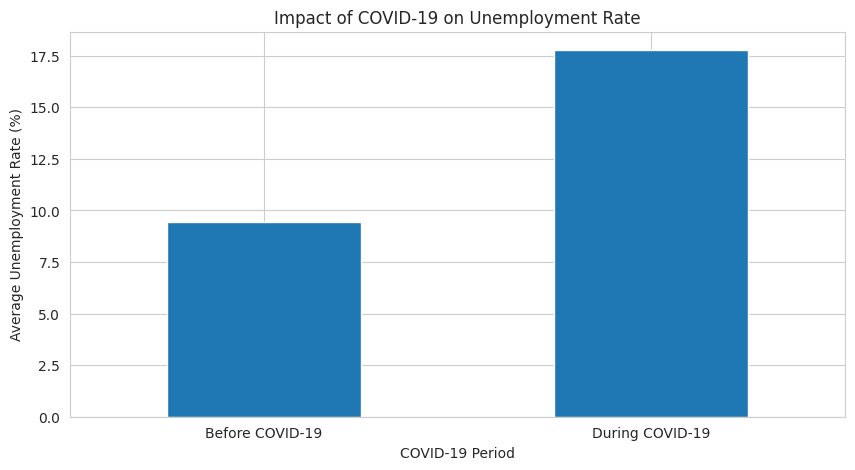

In [29]:
#Visualize COVID-19 impact
plt.figure(figsize=(10, 5))

covid_analysis.plot(kind='bar')

plt.title("Impact of COVID-19 on Unemployment Rate")

plt.xlabel("COVID-19 Period")

plt.ylabel("Average Unemployment Rate (%)")

plt.xticks(rotation=0)

plt.show()

In [30]:
#Calculate percentage change
before = covid_analysis.get('Before COVID-19', np.nan)

during = covid_analysis.get('During COVID-19', np.nan)

after = covid_analysis.get('After COVID-19', np.nan)

if pd.notna(before) and before != 0:
    covid_increase = ((during - before) / before) * 100

    print("Change during COVID-19 compared to before:",
          round(covid_increase, 2), "%")

if pd.notna(after) and during != 0:
    recovery = ((after - during) / during) * 100

    print("Change after COVID-19 compared to during:",
          round(recovery, 2), "%")

Change during COVID-19 compared to before: 88.05 %


In [31]:
#Monthly and Seasonal Trend Analysis
df['Year'] = df['Date'].dt.year

df['Month'] = df['Date'].dt.month

df['Month_Name'] = df['Date'].dt.month_name()

print(df[['Date', 'Year', 'Month', 'Month_Name']].head())

          Date  Year  Month Month_Name
0   2019-05-31  2019      5        May
189 2019-05-31  2019      5        May
740 2019-05-31  2019      5        May
519 2019-05-31  2019      5        May
40  2019-05-31  2019      5        May


In [32]:
#Calculate monthly unemployment rate
monthly_analysis = df.groupby('Month')[
    'Estimated Unemployment Rate (%)'
].mean()

print(monthly_analysis)

Month
1      9.950755
2      9.964717
3     10.700577
4     23.641569
5     16.646190
6     10.553462
7      9.033889
8      9.637925
9      9.051731
10     9.900909
11     9.356145
12     9.497358
Name: Estimated Unemployment Rate (%), dtype: float64


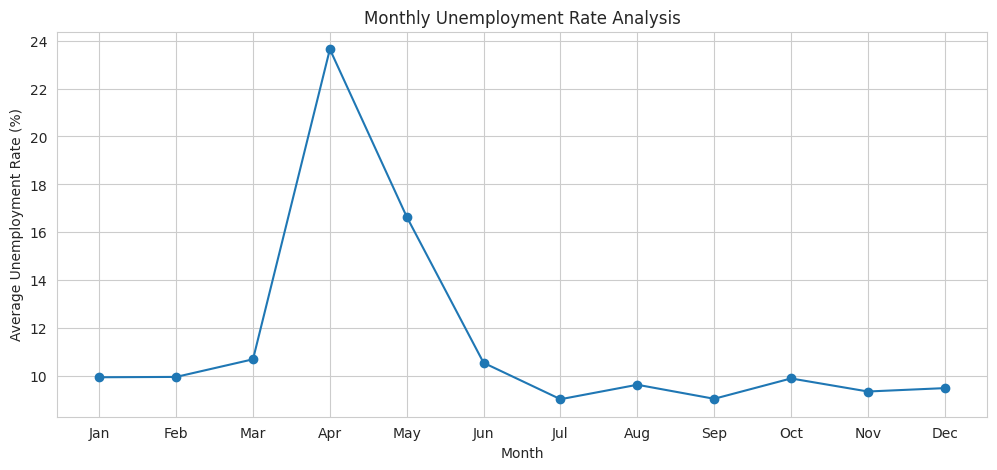

In [33]:
#Visualize monthly unemployment trends
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_analysis.index,
    monthly_analysis.values,
    marker='o'
)

plt.title("Monthly Unemployment Rate Analysis")

plt.xlabel("Month")

plt.ylabel("Average Unemployment Rate (%)")

plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

plt.grid(True)

plt.show()

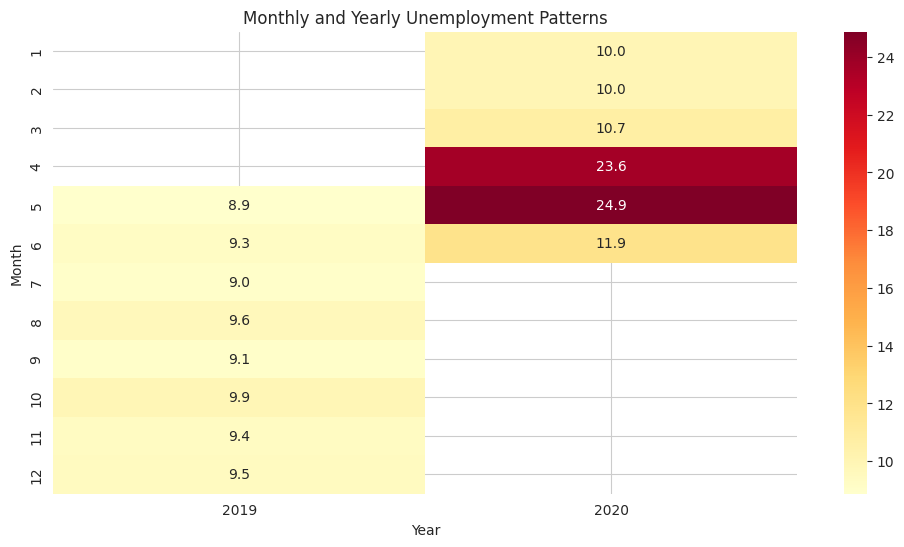

In [34]:
#Seasonal analysis across years
seasonal_data = df.pivot_table(
    values='Estimated Unemployment Rate (%)',
    index='Month',
    columns='Year',
    aggfunc='mean'
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    seasonal_data,
    annot=True,
    cmap='YlOrRd',
    fmt='.1f'
)

plt.title("Monthly and Yearly Unemployment Patterns")

plt.xlabel("Year")

plt.ylabel("Month")

plt.show()

In [35]:
#Yearly Unemployment Analysis
yearly_analysis = df.groupby('Year')[
    'Estimated Unemployment Rate (%)'
].mean()

print(yearly_analysis)

Year
2019     9.334913
2020    15.101581
Name: Estimated Unemployment Rate (%), dtype: float64


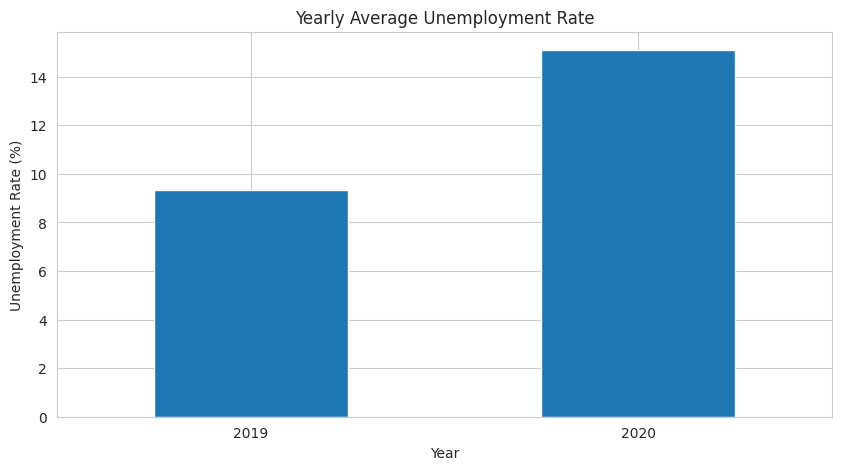

In [36]:
#Viisualize yearly trends
plt.figure(figsize=(10, 5))

yearly_analysis.plot(kind='bar')

plt.title("Yearly Average Unemployment Rate")

plt.xlabel("Year")

plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=0)

plt.show()

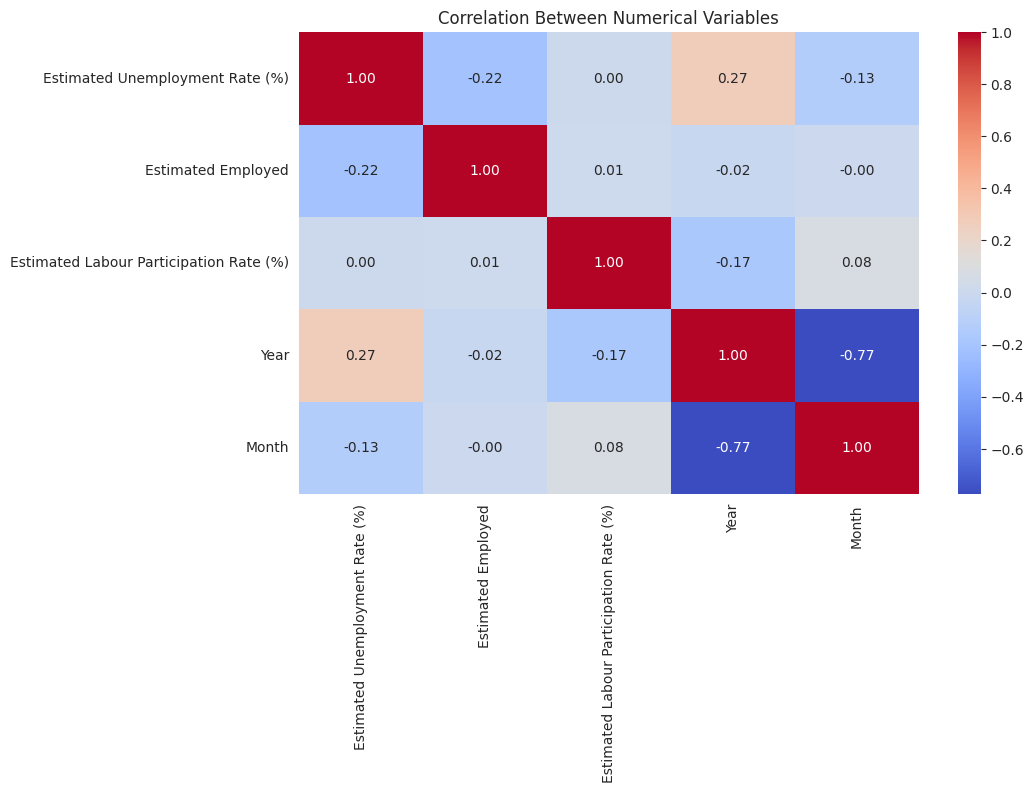

In [37]:
#Correlation Analysis
plt.figure(figsize=(10, 6))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Between Numerical Variables")

plt.show()

In [38]:
#Top 10 Regions with Highest Unemployment
top_regions = df.groupby('Region')[
    'Estimated Unemployment Rate (%)'
].mean().sort_values(ascending=False).head(10)

print("Top 10 Regions with Highest Unemployment:")

print(top_regions)

Top 10 Regions with Highest Unemployment:
Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: Estimated Unemployment Rate (%), dtype: float64


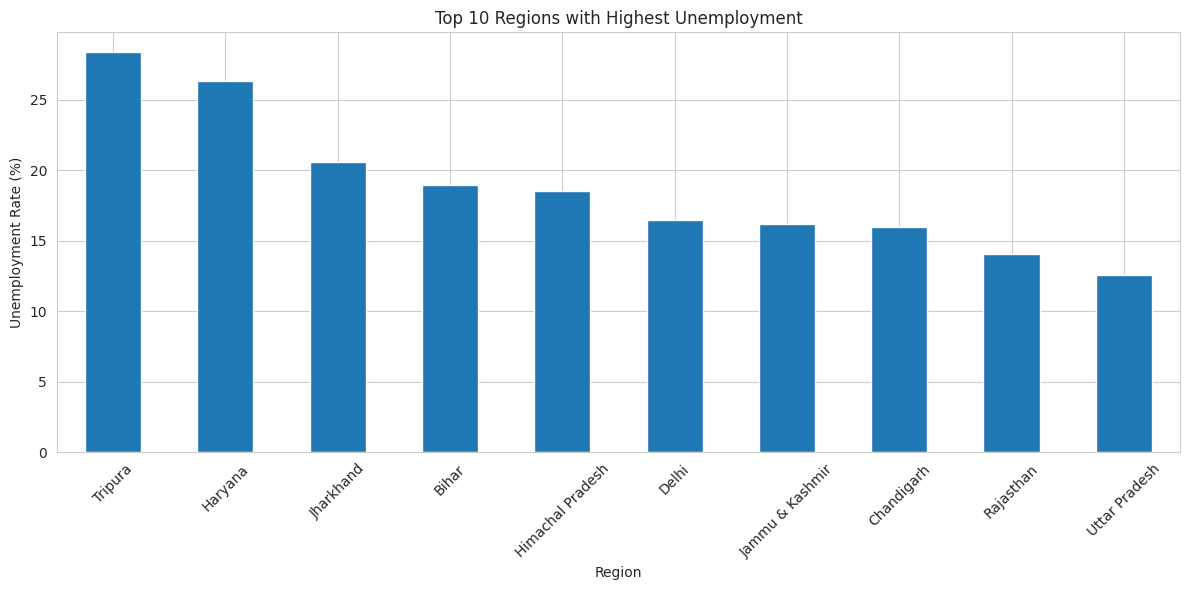

In [39]:
#Visualization
plt.figure(figsize=(12, 6))

top_regions.plot(kind='bar')

plt.title("Top 10 Regions with Highest Unemployment")

plt.xlabel("Region")

plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [41]:
#Generate Automatic Insights
print("=" * 55)

print("=" * 55)


# Overall unemployment

print("\n1. Overall Average Unemployment Rate:")

print(round(df['Estimated Unemployment Rate (%)'].mean(), 2), "%")


# Highest unemployment region

print("\n2. Highest Unemployment Region:")

print(region_data.idxmax())


# Lowest unemployment region

print("\n3. Lowest Unemployment Region:")

print(region_data.idxmin())


# COVID impact

print("\n4. COVID-19 Impact:")

print(covid_analysis)


# Monthly analysis

print("\n5. Monthly Unemployment Analysis:")

print(monthly_analysis)


# Yearly analysis

print("\n6. Yearly Unemployment Analysis:")

print(yearly_analysis)


# Highest unemployment month

print("\n7. Month with Highest Average Unemployment:")

print(monthly_analysis.idxmax())


# Lowest unemployment month

print("\n8. Month with Lowest Average Unemployment:")

print(monthly_analysis.idxmin())


print("\n" + "=" * 55)

print("=" * 55)


1. Overall Average Unemployment Rate:
11.66 %

2. Highest Unemployment Region:
Tripura

3. Lowest Unemployment Region:
Meghalaya

4. COVID-19 Impact:
COVID_Period
Before COVID-19     9.451968
During COVID-19    17.774363
Name: Estimated Unemployment Rate (%), dtype: float64

5. Monthly Unemployment Analysis:
Month
1      9.950755
2      9.964717
3     10.700577
4     23.641569
5     16.646190
6     10.553462
7      9.033889
8      9.637925
9      9.051731
10     9.900909
11     9.356145
12     9.497358
Name: Estimated Unemployment Rate (%), dtype: float64

6. Yearly Unemployment Analysis:
Year
2019     9.334913
2020    15.101581
Name: Estimated Unemployment Rate (%), dtype: float64

7. Month with Highest Average Unemployment:
4

8. Month with Lowest Average Unemployment:
7



In [42]:
# Save cleaned dataset

df.to_csv(
    "Cleaned_Unemployment_Data.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
